In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#Load the cleaned dataset
df = pd.read_csv(
    "../Day-08-Data-Cleaning-and-Preprocessing/cleaned_student_data.csv"
)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,student_name,age,marks,department
0,Sai,20,85.0,CSE
1,Ravi,21,90.0,ECE
2,Anu,20,78.0,CSE
3,Kiran,20,89.0,IT
4,Meena,20,88.0,CSE


In [3]:
#Understand the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

Dataset shape: (7, 4)

Column names:
['student_name', 'age', 'marks', 'department']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   student_name  7 non-null      str    
 1   age           7 non-null      int64  
 2   marks         7 non-null      float64
 3   department    7 non-null      str    
dtypes: float64(1), int64(1), str(2)
memory usage: 406.0 bytes

First five rows:


,student_name,age,marks,department
0,Sai,20,85.0,CSE
1,Ravi,21,90.0,ECE
2,Anu,20,78.0,CSE
3,Kiran,20,89.0,IT
4,Meena,20,88.0,CSE



Last five rows:


,student_name,age,marks,department
2,Anu,20,78.0,CSE
3,Kiran,20,89.0,IT
4,Meena,20,88.0,CSE
5,Arjun,22,89.0,ECE
6,Divya,19,92.0,CSE


In [4]:
#Check data quality
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique departments:")
print(df["department"].unique())

Missing values:
student_name    0
age             0
marks           0
department      0
dtype: int64

Duplicate rows: 0

Unique departments:
<ArrowStringArray>
['CSE', 'ECE', 'IT']
Length: 3, dtype: str


In [5]:
#Descriptive statistics
print("Numerical descriptive statistics:")
display(df.describe())

print("\nStudent count by department:")
display(df["department"].value_counts())

print("\nMarks statistics:")
print("Average marks:", round(df["marks"].mean(), 2))
print("Median marks:", df["marks"].median())
print("Highest marks:", df["marks"].max())
print("Lowest marks:", df["marks"].min())
print("Standard deviation:", round(df["marks"].std(), 2))

Numerical descriptive statistics:


,age,marks
count,7.000000,7.000000
mean,20.285714,87.285714
std,0.951190,4.608481
min,19.000000,78.000000
25%,20.000000,86.500000
50%,20.000000,89.000000
75%,20.500000,89.500000
max,22.000000,92.000000



Student count by department:


department
CSE    4
ECE    2
IT     1
Name: count, dtype: int64


Marks statistics:
Average marks: 87.29
Median marks: 89.0
Highest marks: 92.0
Lowest marks: 78.0
Standard deviation: 4.61


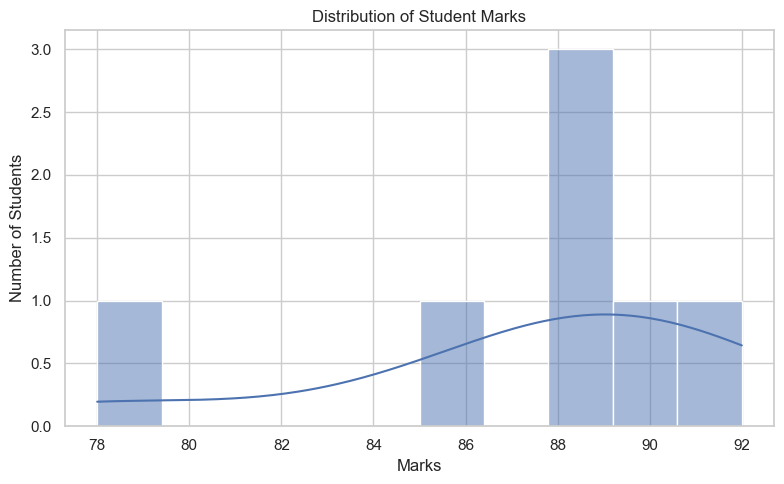

In [6]:
#Histogram(Distribution of student marks)
plt.figure()
sns.histplot(data=df, x="marks", bins=10, kde=True)
plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

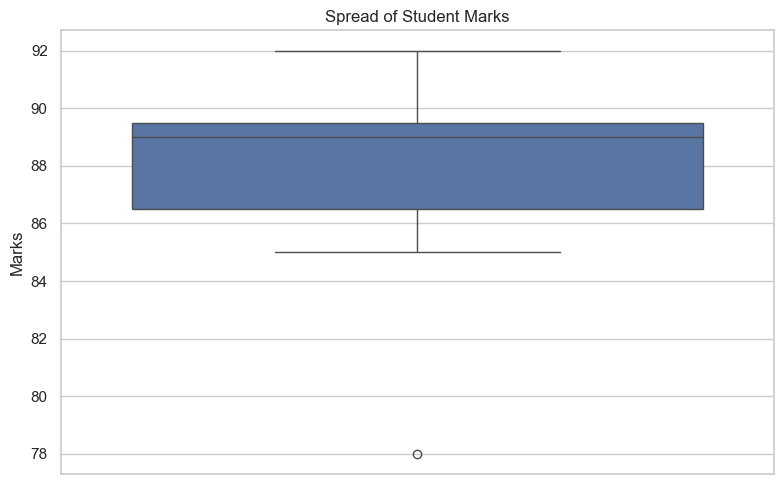

In [7]:
#Box plot
plt.figure()
sns.boxplot(data=df, y="marks")
plt.title("Spread of Student Marks")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

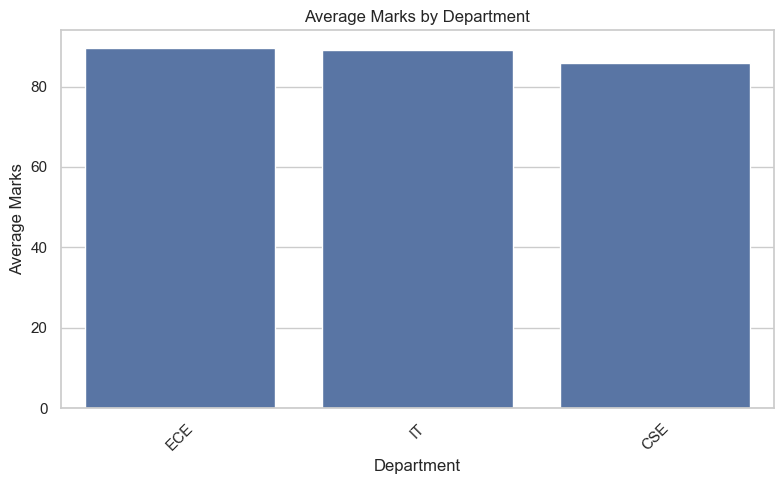

In [8]:
#Average marks by department
department_marks = df.groupby("department")["marks"].mean().sort_values(
    ascending=False
)

plt.figure()
sns.barplot(x=department_marks.index, y=department_marks.values)
plt.title("Average Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

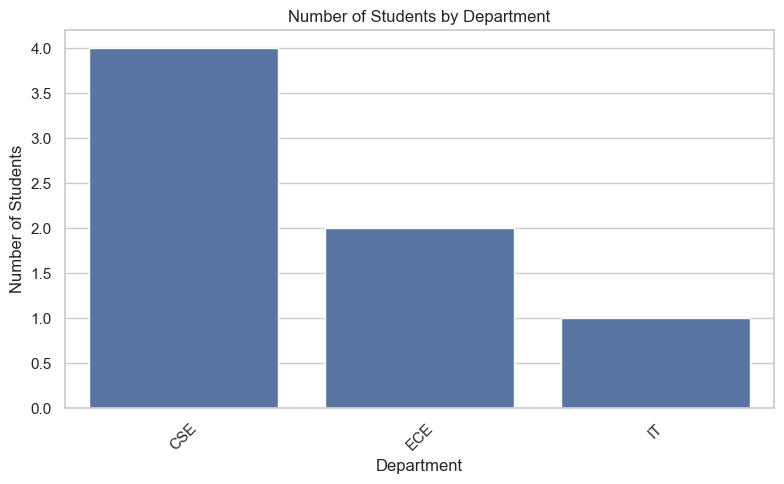

In [9]:

#Number of students by department
plt.figure()
sns.countplot(data=df, x="department")
plt.title("Number of Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

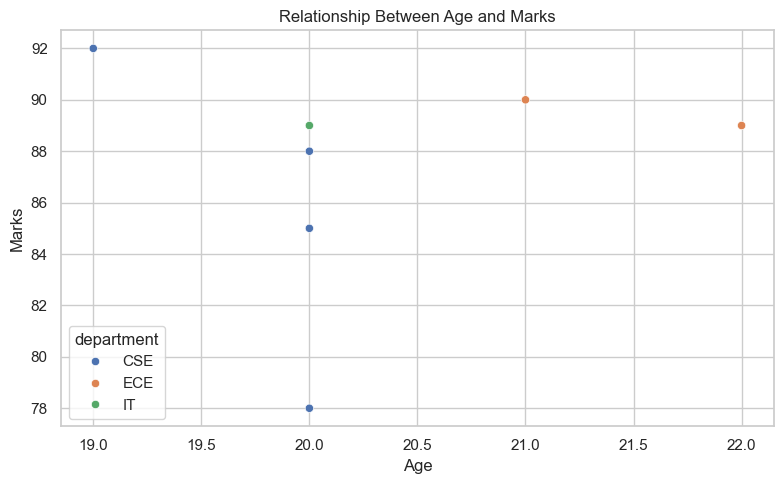

In [10]:
#Age versus marks
plt.figure()
sns.scatterplot(data=df, x="age", y="marks", hue="department")
plt.title("Relationship Between Age and Marks")
plt.xlabel("Age")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

In [11]:
#five business insights from the actual data
department_summary = df.groupby("department").agg(
    student_count=("student_name", "count"),
    average_marks=("marks", "mean"),
    highest_marks=("marks", "max"),
    lowest_marks=("marks", "min")
).round(2)

print("1. Overall average marks:", round(df["marks"].mean(), 2))

print("\n2. Highest-performing department:")
print(department_summary["average_marks"].idxmax())

print("\n3. Lowest-performing department:")
print(department_summary["average_marks"].idxmin())

print("\n4. Department with the most students:")
print(department_summary["student_count"].idxmax())

print("\n5. Department performance summary:")
display(department_summary)

1. Overall average marks: 87.29

2. Highest-performing department:
ECE

3. Lowest-performing department:
CSE

4. Department with the most students:
CSE

5. Department performance summary:


,student_count,average_marks,highest_marks,lowest_marks
department,,,,
CSE,4,85.75,92.0,78.0
ECE,2,89.50,90.0,89.0
IT,1,89.00,89.0,89.0
